# Assignment 7 - Noun Phrase Identification using an HMM

**Name:** Tanu Meena  
**Roll number:** U23AI076

A noun phrase can contain one or more words. We predict one tag per word:
`B-NP` starts a noun phrase, `I-NP` continues it, and `O` marks other words.

This notebook implements a supervised Hidden Markov Model (HMM), the forward
algorithm, and Viterbi decoding **from scratch using NumPy**. It follows the
count-based probability calculations in `Assign4_NGram.ipynb`, including
**Add-K smoothing with K = 0.1**, and the explanation/result/artifact structure
of Assignment 6. Lab 7 supplies its own English data, so the previous Hindi
and language-identification datasets are not used for this task.

References: the supplied `ILLM-Lab7-Assignment.pdf`,
[seqeval](https://pypi.org/project/seqeval/), and
[Jurafsky and Martin, HMMs](https://web.stanford.edu/~jurafsky/slp3/A.pdf).

## 1. Setup

Run cells from top to bottom. From a terminal, install dependencies with
`python -m pip install -r Lab7/requirements-assignment7.txt` from the parent
assignment folder. The notebook works from either that folder or `Lab7`.
There are no downloads, pretrained models, or stochastic training steps.

In [1]:
import hashlib
import json
import math
from collections import Counter
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from seqeval.metrics import (
    classification_report, f1_score, precision_score, recall_score,
)
from seqeval.scheme import IOB2

if (Path.cwd() / "Data" / "train_NP.txt").is_file():
    LAB_DIR = Path.cwd()
elif (Path.cwd() / "Lab7" / "Data" / "train_NP.txt").is_file():
    LAB_DIR = Path.cwd() / "Lab7"
elif "__file__" in globals():
    LAB_DIR = Path(__file__).resolve().parent
else:
    raise FileNotFoundError("Open this notebook from Lab7 or its parent folder.")

TRAIN_FILE = LAB_DIR / "Data" / "train_NP.txt"
TEST_FILE = LAB_DIR / "Data" / "test_NP.txt"
OUTPUT_DIR = LAB_DIR / "assignment7_artifacts"
MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = OUTPUT_DIR / "plots"
for directory in (OUTPUT_DIR, MODEL_DIR, PLOT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

TAGS = ("B-NP", "I-NP", "O")
TAG_TO_ID = {tag: i for i, tag in enumerate(TAGS)}
ADD_K = 0.1
MIN_WORD_COUNT = 2
UNK = "<UNK>"


def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2),
                          encoding="utf-8")


print("Data directory:", TRAIN_FILE.parent)
print("Tags:", TAGS)
print(f"Add-K = {ADD_K}; minimum word count = {MIN_WORD_COUNT}")

Data directory: c:\Users\Tanu Meena\OneDrive\Desktop\llm\Lab7\Data
Tags: ('B-NP', 'I-NP', 'O')
Add-K = 0.1; minimum word count = 2


## 2. Read and inspect the supplied data

Each nonempty line contains `word<TAB>tag`; a blank line ends a sentence.
We preserve word spelling, punctuation, capitalization, and sentence order.
The final sentence is also read when a file has no trailing blank line.
The supplied labels use valid IOB2: a sentence cannot begin with `I-NP`,
and `I-NP` cannot immediately follow `O`.

In [2]:
def validate_bio(tags):
    for position, tag in enumerate(tags):
        if tag not in TAG_TO_ID:
            raise ValueError(f"Unknown tag: {tag!r}")
        if tag == "I-NP" and (position == 0 or tags[position - 1] == "O"):
            raise ValueError(f"Invalid IOB2 continuation at position {position}.")


def read_tagged_sentences(path):
    sentences, words, tags = [], [], []
    for line_number, line in enumerate(
            Path(path).read_text(encoding="utf-8").splitlines() + [""], start=1):
        if not line.strip():
            if words:
                validate_bio(tags)
                sentences.append((words, tags))
                words, tags = [], []
            continue
        columns = line.split()
        if len(columns) != 2:
            raise ValueError(f"{path}:{line_number}: expected one word and one tag.")
        word, tag = columns
        words.append(word)
        tags.append(tag)
    if not sentences:
        raise ValueError(f"No sentences found in {path}.")
    return sentences


train_sentences = read_tagged_sentences(TRAIN_FILE)
test_sentences = read_tagged_sentences(TEST_FILE)
train_words = {word for words, _ in train_sentences for word in words}
dataset_rows, tag_count_rows = [], []
for split, sentences in [("train", train_sentences), ("test", test_sentences)]:
    lengths = [len(words) for words, _ in sentences]
    counts = Counter(tag for _, tags in sentences for tag in tags)
    dataset_rows.append({
        "split": split, "sentences": len(sentences), "tokens": sum(lengths),
        "unique_words": len({word for words, _ in sentences for word in words}),
        "min_length": min(lengths), "max_length": max(lengths),
        "mean_length": float(np.mean(lengths)),
    })
    tag_count_rows.append({"split": split, **{tag: counts[tag] for tag in TAGS}})

dataset_df = pd.DataFrame(dataset_rows)
tag_counts_df = pd.DataFrame(tag_count_rows)
dataset_df.to_csv(OUTPUT_DIR / "dataset_summary.csv", index=False)
tag_counts_df.to_csv(OUTPUT_DIR / "tag_counts.csv", index=False)
display(dataset_df)
display(tag_counts_df)
display(pd.DataFrame({"word": train_sentences[0][0],
                      "gold_tag": train_sentences[0][1]}))

,split,sentences,tokens,unique_words,min_length,max_length,mean_length
0,train,823,19172,4570,1,63,23.295261
1,test,77,1896,744,4,50,24.623377


,split,B-NP,I-NP,O
0,train,5051,5727,8394
1,test,475,579,842


,word,gold_tag
0,Rockwell,B-NP
1,International,I-NP
2,Corp.,I-NP
3,'s,B-NP
4,Tulsa,I-NP
5,unit,I-NP
6,said,O
7,it,B-NP
8,signed,O
9,a,B-NP


## 3. Estimate the HMM parameters from training counts

The hidden state is the NP tag; the observation is the word. A first-order
HMM assumes the next tag depends only on the previous tag and a word depends
only on its current tag. For a sentence of a supplied length T:

$$P(w_{1:T},z_{1:T}\mid T)=\pi_{z_1}b_{z_1}(w_1)
  \prod_{t=2}^{T}a_{z_{t-1},z_t}b_{z_t}(w_t).$$

We use the standard fixed-length HMM convention, without an END state or a
separate distribution over sentence lengths. The sentence likelihood sums
this expression over hidden tag paths.

For allowed initial tags J and allowed successors J(i), Add-K gives:

$$\pi_j=\frac{C_{start}(j)+K}{N_{sentences}+K|J|},\qquad
a_{ij}=\frac{C(i,j)+K}{\sum_{u\in J(i)}C(i,u)+K|J(i)|},$$
$$b_j(w)=\frac{C(j,w)+K}{C(j)+K|V|}.$$

Transition counts never cross sentence boundaries. Structurally invalid
IOB2 starts/transitions remain zero, while allowed zero-count events receive
smoothing. Every probability distribution is normalized over its support.

**Unknown words:** only training counts build V. Training words occurring
once are pooled into `<UNK>` (MIN_WORD_COUNT = 2); unseen test words use the
same symbol. This learns an unknown-word emission distribution from training
data. Likelihoods therefore describe the **mapped observation sequence**,
where rare/unseen surface words share `<UNK>`. We use the fixed settings
above without selecting parameters on test labels.

In [3]:
class HiddenMarkovModel:
    def __init__(self, add_k=0.1, min_word_count=2):
        if not math.isfinite(add_k) or add_k <= 0:
            raise ValueError("add_k must be finite and positive.")
        if not isinstance(min_word_count, int) or min_word_count < 1:
            raise ValueError("min_word_count must be a positive integer.")
        self.add_k = float(add_k)
        self.min_word_count = min_word_count
        self.tags = TAGS

    def fit(self, sentences):
        if not sentences:
            raise ValueError("Training data must be nonempty.")
        for words, tags in sentences:
            if not words or len(words) != len(tags):
                raise ValueError("Each training sentence needs aligned words/tags.")
            validate_bio(tags)
        self.word_counts = Counter(word for words, _ in sentences for word in words)
        if UNK in self.word_counts:
            raise ValueError(f"{UNK} is reserved for the unknown-word symbol.")
        self.vocabulary = [UNK] + sorted(
            word for word, count in self.word_counts.items()
            if count >= self.min_word_count)
        self.word_to_id = {word: i for i, word in enumerate(self.vocabulary)}
        number_of_tags = len(self.tags)
        self.start_counts = np.zeros(number_of_tags, dtype=np.int64)
        self.transition_counts = np.zeros((number_of_tags, number_of_tags), dtype=np.int64)
        self.emission_counts = np.zeros((number_of_tags, len(self.vocabulary)), dtype=np.int64)

        for words, tags in sentences:
            states = [TAG_TO_ID[tag] for tag in tags]
            self.start_counts[states[0]] += 1
            for position, (word, state) in enumerate(zip(words, states)):
                self.emission_counts[state, self.word_to_id.get(word, 0)] += 1
                if position:
                    self.transition_counts[states[position - 1], state] += 1

        self.allowed_start = np.array([True, False, True])
        self.allowed_transition = np.ones((number_of_tags, number_of_tags), dtype=bool)
        self.allowed_transition[TAG_TO_ID["O"], TAG_TO_ID["I-NP"]] = False

        starts = self.start_counts + self.add_k * self.allowed_start
        self.initial = starts / starts.sum()
        transitions = self.transition_counts + self.add_k * self.allowed_transition
        self.transition = transitions / transitions.sum(axis=1, keepdims=True)
        emissions = self.emission_counts + self.add_k
        self.emission = emissions / emissions.sum(axis=1, keepdims=True)

        # log(0) = -inf represents structurally impossible tag paths.
        with np.errstate(divide="ignore"):
            self.log_initial = np.log(self.initial)
            self.log_transition = np.log(self.transition)
            self.log_emission = np.log(self.emission)

        np.testing.assert_allclose(self.initial.sum(), 1.0)
        np.testing.assert_allclose(self.transition.sum(axis=1), 1.0)
        np.testing.assert_allclose(self.emission.sum(axis=1), 1.0)
        assert self.initial[1] == 0 and self.transition[2, 1] == 0
        assert np.all(self.emission > 0)
        return self

    def encode(self, words):
        return np.array([self.word_to_id.get(word, 0) for word in words], dtype=np.int64)

    def save(self, directory):
        directory = Path(directory)
        directory.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(
            directory / "hmm_parameters.npz", initial=self.initial,
            transition=self.transition, emission=self.emission,
            start_counts=self.start_counts, transition_counts=self.transition_counts,
            emission_counts=self.emission_counts,
        )
        write_json(directory / "hmm_metadata.json", {
            "tags": list(self.tags), "vocabulary": self.vocabulary,
            "add_k": self.add_k, "min_word_count": self.min_word_count,
            "observation_mapping": "case-sensitive; rare and unseen words use <UNK>",
            "length_convention": "fixed-length HMM; no END state",
            "constraints": "IOB2: no initial I-NP and no O -> I-NP",
        })


hmm = HiddenMarkovModel(ADD_K, MIN_WORD_COUNT).fit(train_sentences)
hmm.save(MODEL_DIR)
initial_df = pd.DataFrame({"tag": TAGS, "count": hmm.start_counts,
                           "probability": hmm.initial})
transition_df = pd.DataFrame(hmm.transition, index=TAGS, columns=TAGS)
emission_df = pd.DataFrame(hmm.emission, index=TAGS, columns=hmm.vocabulary).T
initial_df.to_csv(OUTPUT_DIR / "initial_probabilities.csv", index=False)
transition_df.to_csv(OUTPUT_DIR / "transition_probabilities.csv", index_label="previous_tag")
emission_df.to_csv(OUTPUT_DIR / "emission_probabilities.csv", index_label="observation")
print("Observation vocabulary including <UNK>:", len(hmm.vocabulary))
print("Training tokens pooled into <UNK>:", int(hmm.emission_counts[:, 0].sum()))
display(initial_df)
display(transition_df)
display(emission_df.loc[[UNK, "the", "said", "."]])

Observation vocabulary including <UNK>: 1760
Training tokens pooled into <UNK>: 2811


,tag,count,probability
0,B-NP,541,0.657313
1,I-NP,0,0.000000
2,O,282,0.342687


,B-NP,I-NP,O
B-NP,0.029523,0.695622,0.274855
I-NP,0.045875,0.387534,0.566590
O,0.540336,0.000000,0.459664


,B-NP,I-NP,O
<UNK>,0.119591,0.242267,0.088226
the,0.154410,0.001033,0.000012
said,0.000019,0.000017,0.011564
.,0.000019,0.002219,0.093244


## 4. Forward algorithm: probability of a sentence

The forward value alpha_t(j) sums the probability of all paths ending in j
after the first t observations:

$$\alpha_1(j)=\pi_j b_j(w_1),\qquad
\alpha_t(j)=b_j(w_t)\sum_i\alpha_{t-1}(i)a_{ij},$$
$$P(w_{1:T}\mid T)=\sum_j\alpha_T(j).$$

Multiplying many small values can underflow. We calculate in log space,
using log-sum-exp (NumPy's `logaddexp.reduce`) for each sum. We save both
the natural log likelihood and its exponentiated probability. If a very
long sentence underflows when exponentiated, its log likelihood stays valid.
Time complexity is O(T S^2), with S = 3; working memory is O(S).

In [4]:
def forward_algorithm(model, words):
    """Return log P(mapped words | supplied length), summing every tag path."""
    observations = model.encode(words)
    if not len(observations):
        return 0.0  # Empty product: P(empty sequence | length 0) = 1.
    log_alpha = model.log_initial + model.log_emission[:, observations[0]]
    for observation in observations[1:]:
        # Rows are previous states i; columns are current states j.
        candidates = log_alpha[:, None] + model.log_transition
        log_alpha = model.log_emission[:, observation] + np.logaddexp.reduce(candidates, axis=0)
    return float(np.logaddexp.reduce(log_alpha))


first_test_words = test_sentences[0][0]
first_log_probability = forward_algorithm(hmm, first_test_words)
print("First test sentence:", " ".join(first_test_words))
print(f"Log probability: {first_log_probability:.8f}")
print(f"Probability: {math.exp(first_log_probability):.8e}")

First test sentence: Confidence in the pound is widely expected to take another sharp dive if trade figures for September , due for release tomorrow , fail to show a substantial improvement from July and August 's near-record deficits .
Log probability: -173.68238110
Probability: 3.72134798e-76


## 5. Viterbi decoding: the most probable tag sequence

Viterbi replaces forward's sum with a maximum. Backpointers retain the
previous state selected for each current state:

$$\delta_1(j)=\log\pi_j+\log b_j(w_1),$$
$$\delta_t(j)=\log b_j(w_t)+\max_i[\delta_{t-1}(i)+\log a_{ij}],$$
$$\psi_t(j)=\arg\max_i[\delta_{t-1}(i)+\log a_{ij}].$$

Start with the best final state, then follow the backpointers to recover
all tags. This finds the best **complete path**, including `O` tags.
Its joint probability is at most the forward likelihood, because the
latter sums over every valid path. Time and memory are O(T S^2) and O(T S).

In [5]:
def viterbi_decode(model, words):
    """Return (best tag sequence, log P(words, best tags | supplied length))."""
    observations = model.encode(words)
    if not len(observations):
        return [], 0.0
    backpointers = np.zeros((len(observations), len(model.tags)), dtype=np.int64)
    delta = model.log_initial + model.log_emission[:, observations[0]]
    for position, observation in enumerate(observations[1:], start=1):
        candidates = delta[:, None] + model.log_transition
        backpointers[position] = np.argmax(candidates, axis=0)
        delta = model.log_emission[:, observation] + np.max(candidates, axis=0)
    final_state = int(np.argmax(delta))
    best_log_probability = float(delta[final_state])
    path = [final_state]
    for position in range(len(observations) - 1, 0, -1):
        path.append(int(backpointers[position, path[-1]]))
    predicted_tags = [model.tags[state] for state in reversed(path)]
    validate_bio(predicted_tags)
    return predicted_tags, best_log_probability


first_predictions, first_path_log_probability = viterbi_decode(hmm, first_test_words)
display(pd.DataFrame({"word": first_test_words, "gold_tag": test_sentences[0][1],
                      "predicted_tag": first_predictions}))
print(f"Best path log probability: {first_path_log_probability:.8f}")
print(f"Forward log probability:   {first_log_probability:.8f}")

,word,gold_tag,predicted_tag
0,Confidence,B-NP,B-NP
1,in,O,O
2,the,B-NP,B-NP
3,pound,I-NP,I-NP
4,is,O,O
5,widely,O,O
6,expected,O,O
7,to,O,O
8,take,O,O
9,another,B-NP,B-NP


Best path log probability: -178.88586252
Forward log probability:   -173.68238110


## 6. Verify the algorithms against exhaustive enumeration

On a tiny training corpus, enumerate all 3^T tag paths for short sentences.
The direct sum must equal forward, and the direct maximum must equal
Viterbi. These checks also cover one-word, unknown-word, and empty inputs.
This verifies the recurrences and backtracking independently of test scores.

In [6]:
def enumerated_path_scores(model, words):
    observations = model.encode(words)
    scores = []
    for path in product(range(len(model.tags)), repeat=len(words)):
        if not path:
            scores.append(([], 0.0))
            continue
        score = model.log_initial[path[0]] + model.log_emission[path[0], observations[0]]
        for position in range(1, len(words)):
            score += (model.log_transition[path[position - 1], path[position]]
                      + model.log_emission[path[position], observations[position]])
        scores.append(([model.tags[state] for state in path], float(score)))
    return scores


toy_model = HiddenMarkovModel(0.1, 1).fit([
    (["the", "cat", "runs"], ["B-NP", "I-NP", "O"]),
    (["a", "dog", "runs"], ["B-NP", "I-NP", "O"]),
    (["runs", "cats"], ["O", "B-NP"]),
    (["cats"], ["B-NP"]),
])
for words in [[], ["cat"], ["never_seen"], ["the", "cat", "runs"],
              ["never_seen", "cat", "also_unseen"]]:
    enumerated = enumerated_path_scores(toy_model, words)
    direct_log_sum = float(np.logaddexp.reduce([score for _, score in enumerated]))
    best_tags, best_score = max(enumerated, key=lambda row: row[1])
    predicted, decoded_score = viterbi_decode(toy_model, words)
    np.testing.assert_allclose(forward_algorithm(toy_model, words), direct_log_sum, atol=1e-12)
    np.testing.assert_allclose(decoded_score, best_score, atol=1e-12)
    assert predicted == best_tags
    assert decoded_score <= direct_log_sum + 1e-12
print("Passed: forward sums, Viterbi maxima/backtracking, empty/single/OOV inputs,")
print("normalized parameters, and valid IOB2 paths.")

Passed: forward sums, Viterbi maxima/backtracking, empty/single/OOV inputs,
normalized parameters, and valid IOB2 paths.


## 7. Score and decode every test sentence

No test labels enter the forward or Viterbi functions. Each result retains
its original sentence number and word order. We save sentence probabilities,
gold/predicted tags, and the exact noun-phrase spans. Span ends are exclusive.

In [7]:
def noun_phrase_spans(words, tags):
    validate_bio(tags)
    spans, start = [], None
    for position, tag in enumerate(list(tags) + ["O"]):
        if start is not None and tag != "I-NP":
            spans.append({"start": start, "end": position,
                          "text": " ".join(words[start:position])})
            start = None
        if tag == "B-NP":
            start = position
    return spans


sentence_rows, token_rows, prediction_records, test_predictions = [], [], [], []
for sentence_id, (words, gold_tags) in enumerate(test_sentences, start=1):
    log_probability = forward_algorithm(hmm, words)
    predictions, path_log_probability = viterbi_decode(hmm, words)
    assert len(predictions) == len(words)
    assert math.isfinite(log_probability) and log_probability <= 1e-12
    assert path_log_probability <= log_probability + 1e-12
    probability = math.exp(log_probability)
    unknown_tokens = int(np.count_nonzero(hmm.encode(words) == 0))
    unseen_tokens = sum(word not in train_words for word in words)
    sentence_rows.append({
        "sentence_id": sentence_id, "length": len(words), "sentence": " ".join(words),
        "forward_log_probability": log_probability,
        "forward_probability": probability,
        "viterbi_log_joint_probability": path_log_probability,
        "mean_negative_log_probability": -log_probability / len(words),
        "unseen_training_tokens": unseen_tokens, "mapped_to_UNK_tokens": unknown_tokens,
        "gold_tags": " ".join(gold_tags), "predicted_tags": " ".join(predictions),
    })
    gold_spans = noun_phrase_spans(words, gold_tags)
    predicted_spans = noun_phrase_spans(words, predictions)
    prediction_records.append({
        "sentence_id": sentence_id, "words": words, "gold_tags": gold_tags,
        "predicted_tags": predictions, "gold_noun_phrases": gold_spans,
        "predicted_noun_phrases": predicted_spans,
        "forward_log_probability": log_probability,
        "forward_probability": probability,
        "viterbi_log_joint_probability": path_log_probability,
    })
    for position, (word, gold, predicted) in enumerate(zip(words, gold_tags, predictions)):
        token_rows.append({
            "sentence_id": sentence_id, "token_index": position, "word": word,
            "gold_tag": gold, "predicted_tag": predicted,
            "unseen_in_training": word not in train_words,
            "mapped_to_UNK": word not in hmm.word_to_id,
        })
    test_predictions.append(predictions)

sentence_results_df = pd.DataFrame(sentence_rows)
token_results_df = pd.DataFrame(token_rows)
sentence_results_df.to_csv(OUTPUT_DIR / "test_sentence_probabilities.csv", index=False,
                           float_format="%.17g")
token_results_df.to_csv(OUTPUT_DIR / "test_token_predictions.csv", index=False)
with (OUTPUT_DIR / "test_predictions.jsonl").open("w", encoding="utf-8") as handle:
    for record in prediction_records:
        handle.write(json.dumps(record, ensure_ascii=False) + "\n")
with (OUTPUT_DIR / "test_predictions.conll").open("w", encoding="utf-8") as handle:
    for (words, gold_tags), predictions in zip(test_sentences, test_predictions):
        for word, gold, predicted in zip(words, gold_tags, predictions):
            handle.write(f"{word}\t{gold}\t{predicted}\n")
        handle.write("\n")

assert len(sentence_results_df) == len(test_sentences)
assert len(token_results_df) == sum(len(words) for words, _ in test_sentences)
assert np.isfinite(sentence_results_df["forward_log_probability"]).all()
print(f"Scored and decoded all {len(test_sentences)} test sentences.")
print("Each probability below is P(mapped sentence | supplied sentence length).")
with pd.option_context("display.max_rows", None, "display.float_format", "{:.6e}".format):
    display(sentence_results_df[["sentence_id", "length", "forward_log_probability",
                                 "forward_probability", "mapped_to_UNK_tokens"]])

Scored and decoded all 77 test sentences.
Each probability below is P(mapped sentence | supplied sentence length).


,sentence_id,length,forward_log_probability,forward_probability,mapped_to_UNK_tokens
0,1,37,-1.736824e+02,3.721348e-76,11
1,2,27,-1.067106e+02,4.530994e-47,10
2,3,29,-1.320945e+02,4.286218e-58,10
3,4,36,-1.977298e+02,1.339780e-86,5
4,5,31,-1.549057e+02,5.312864e-68,8
5,6,36,-1.800113e+02,6.638678e-79,9
6,7,39,-1.913369e+02,8.006241e-84,10
7,8,25,-9.887880e+01,1.141514e-43,10
8,9,28,-1.399572e+02,1.649578e-61,8
9,10,24,-1.064110e+02,6.113606e-47,8


## 8. Evaluate exact noun-phrase spans with seqeval

Precision = correct predicted NP spans / predicted NP spans; recall = correct
predicted NP spans / gold NP spans; F1 is their harmonic mean. A span counts
as correct only if both its boundaries match exactly. We explicitly use
`mode='strict', scheme=IOB2`. The `O` tag participates in decoding and token
evaluation, but it is not an entity and is excluded from NP-span F1.

We also report token accuracy and per-tag precision/recall/F1 from a custom
confusion matrix. Token accuracy alone can hide incorrect NP boundaries.

In [8]:
gold_test_tags = [tags for _, tags in test_sentences]
seqeval_options = {"mode": "strict", "scheme": IOB2, "zero_division": 0}
np_precision = float(precision_score(gold_test_tags, test_predictions, **seqeval_options))
np_recall = float(recall_score(gold_test_tags, test_predictions, **seqeval_options))
np_f1 = float(f1_score(gold_test_tags, test_predictions, **seqeval_options))
seqeval_report = classification_report(
    gold_test_tags, test_predictions, digits=4, **seqeval_options)
(OUTPUT_DIR / "seqeval_report.txt").write_text(seqeval_report, encoding="utf-8")

confusion = np.zeros((len(TAGS), len(TAGS)), dtype=np.int64)
for record in token_rows:
    confusion[TAG_TO_ID[record["gold_tag"]], TAG_TO_ID[record["predicted_tag"]]] += 1
confusion_df = pd.DataFrame(confusion, index=TAGS, columns=TAGS)
confusion_df.to_csv(OUTPUT_DIR / "test_confusion_matrix.csv", index_label="gold_tag")
token_accuracy = float(np.trace(confusion) / confusion.sum())
per_tag_rows = []
for state, tag in enumerate(TAGS):
    tp = int(confusion[state, state])
    fp = int(confusion[:, state].sum()) - tp
    fn = int(confusion[state].sum()) - tp
    per_tag_rows.append({
        "tag": tag, "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "f1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
        "support": int(confusion[state].sum()),
    })
per_tag_df = pd.DataFrame(per_tag_rows)
per_tag_df.to_csv(OUTPUT_DIR / "test_per_tag_metrics.csv", index=False)

# Independent exact-span counts must agree with seqeval.
true_positive_spans = gold_span_count = predicted_span_count = 0
for record in prediction_records:
    gold_set = {(span["start"], span["end"]) for span in record["gold_noun_phrases"]}
    predicted_set = {(span["start"], span["end"]) for span in record["predicted_noun_phrases"]}
    true_positive_spans += len(gold_set & predicted_set)
    gold_span_count += len(gold_set)
    predicted_span_count += len(predicted_set)
np.testing.assert_allclose(np_precision, true_positive_spans / predicted_span_count)
np.testing.assert_allclose(np_recall, true_positive_spans / gold_span_count)
np.testing.assert_allclose(np_f1, 2 * true_positive_spans / (gold_span_count + predicted_span_count))

unseen_mask = token_results_df["unseen_in_training"].to_numpy(dtype=bool)
unk_mask = token_results_df["mapped_to_UNK"].to_numpy(dtype=bool)
correct_mask = (token_results_df["gold_tag"] == token_results_df["predicted_tag"]).to_numpy()


def subset_accuracy(mask):
    return float(correct_mask[mask].mean()) if mask.any() else None


train_sentence_set = {tuple(words) for words, _ in train_sentences}
overlap_count = sum(tuple(words) in train_sentence_set for words, _ in test_sentences)
metrics = {
    "train_sentences": len(train_sentences), "test_sentences": len(test_sentences),
    "test_tokens": len(token_rows), "add_k": ADD_K, "min_word_count": MIN_WORD_COUNT,
    "observation_vocabulary_size": len(hmm.vocabulary),
    "np_span_precision": np_precision, "np_span_recall": np_recall, "np_span_f1": np_f1,
    "correct_np_spans": true_positive_spans, "gold_np_spans": gold_span_count,
    "predicted_np_spans": predicted_span_count, "token_accuracy": token_accuracy,
    "token_macro_f1": float(per_tag_df["f1"].mean()),
    "unseen_training_tokens": int(unseen_mask.sum()),
    "unseen_training_token_rate": float(unseen_mask.mean()),
    "unseen_training_token_accuracy": subset_accuracy(unseen_mask),
    "seen_training_token_accuracy": subset_accuracy(~unseen_mask),
    "mapped_to_UNK_tokens": int(unk_mask.sum()),
    "mapped_to_UNK_token_rate": float(unk_mask.mean()),
    "mapped_to_UNK_token_accuracy": subset_accuracy(unk_mask),
    "test_sentences_also_in_train": overlap_count,
    "test_total_log_likelihood": float(sentence_results_df["forward_log_probability"].sum()),
    "probability_underflow_sentences": int((sentence_results_df["forward_probability"] == 0).sum()),
    "seqeval_mode": "strict IOB2",
    "algorithm_checks": "exhaustive sum/max, normalization, empty/single/OOV, BIO, span agreement",
    "train_sha256": hashlib.sha256(TRAIN_FILE.read_bytes()).hexdigest(),
    "test_sha256": hashlib.sha256(TEST_FILE.read_bytes()).hexdigest(),
}
write_json(OUTPUT_DIR / "evaluation_metrics.json", metrics)
evaluation_df = pd.DataFrame([{
    "Model": "Supervised HMM", "NP_Precision": np_precision, "NP_Recall": np_recall,
    "NP_F1": np_f1, "Token_Accuracy": token_accuracy,
}])
evaluation_df.to_csv(OUTPUT_DIR / "assignment7_results.csv", index=False)
print(seqeval_report)
display(evaluation_df)
display(per_tag_df)
print(f"Correct NP spans: {true_positive_spans}/{gold_span_count} gold; "
      f"{predicted_span_count} predicted")
print(f"Unseen training tokens: {unseen_mask.sum()}/{len(unseen_mask)} "
      f"({unseen_mask.mean():.2%})")
print("Test sentences also present in training:", overlap_count)

              precision    recall  f1-score   support

          NP     0.6840    0.6653    0.6745       475

   micro avg     0.6840    0.6653    0.6745       475
   macro avg     0.6840    0.6653    0.6745       475
weighted avg     0.6840    0.6653    0.6745       475



,Model,NP_Precision,NP_Recall,NP_F1,Token_Accuracy
0,Supervised HMM,0.683983,0.665263,0.674493,0.852848


,tag,precision,recall,f1,support
0,B-NP,0.829004,0.806316,0.817503,475
1,I-NP,0.832504,0.867012,0.849408,579
2,O,0.880866,0.869359,0.875075,842


Correct NP spans: 316/475 gold; 462 predicted
Unseen training tokens: 370/1896 (19.51%)
Test sentences also present in training: 0


## 9. Inspect predictions and errors

The first three examples follow the supplied test order. The error table
lists missed gold spans and extra predicted spans, so boundary errors can
be inspected directly. Unknown words and the HMM's limited word/context
representation can affect both labels and phrase boundaries.


Sentence 1: Confidence in the pound is widely expected to take another sharp dive if trade figures for September , due for release tomorrow , fail to show a substantial improvement from July and August 's near-record deficits .
Gold noun phrases: ['Confidence', 'the pound', 'another sharp dive', 'trade figures', 'September', 'release', 'tomorrow', 'a substantial improvement', 'July and August', "'s near-record deficits"]
Predicted noun phrases: ['Confidence', 'the pound', 'another sharp dive', 'trade figures', 'September', 'release tomorrow', 'a substantial improvement', 'July and August', "'s near-record deficits"]

Sentence 2: Chancellor of the Exchequer Nigel Lawson 's restated commitment to a firm monetary policy has helped to prevent a freefall in sterling over the past week .
Gold noun phrases: ['the Exchequer', "'s restated commitment", 'a firm monetary policy', 'a freefall', 'sterling', 'the past week']
Predicted noun phrases: ['Chancellor', 'the Exchequer Nigel', "'s restated

,sentence_id,error,start,end,text
0,1,missed_gold_span,20,21,release
1,1,missed_gold_span,21,22,tomorrow
2,1,extra_predicted_span,20,22,release tomorrow
3,2,missed_gold_span,2,4,the Exchequer
4,2,missed_gold_span,21,22,sterling
5,2,extra_predicted_span,0,1,Chancellor
6,2,extra_predicted_span,2,5,the Exchequer Nigel
7,3,missed_gold_span,1,2,analysts
8,3,missed_gold_span,3,5,underlying support
9,3,missed_gold_span,6,7,sterling


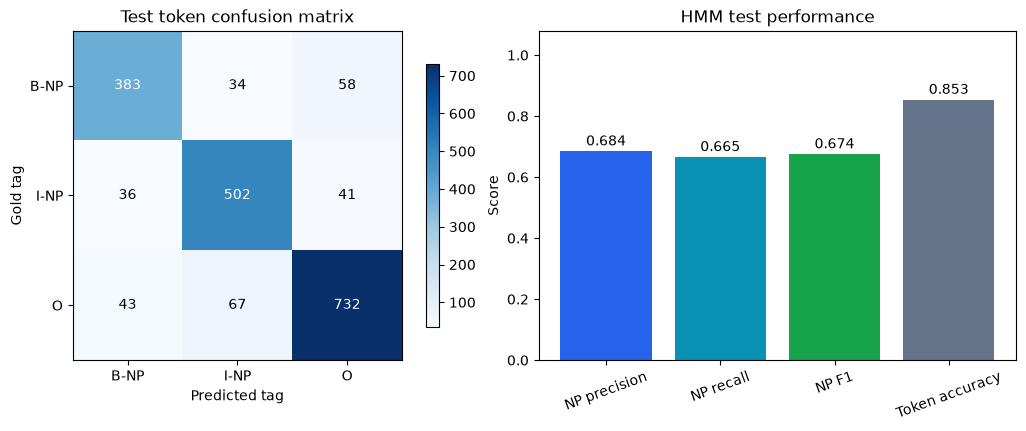

In [9]:
for record in prediction_records[:3]:
    print(f"\nSentence {record['sentence_id']}: {' '.join(record['words'])}")
    print("Gold noun phrases:", [span["text"] for span in record["gold_noun_phrases"]])
    print("Predicted noun phrases:", [span["text"] for span in record["predicted_noun_phrases"]])

error_rows = []
for record in prediction_records:
    gold_lookup = {(span["start"], span["end"]): span["text"]
                   for span in record["gold_noun_phrases"]}
    predicted_lookup = {(span["start"], span["end"]): span["text"]
                        for span in record["predicted_noun_phrases"]}
    for span in sorted(gold_lookup.keys() - predicted_lookup.keys()):
        error_rows.append({"sentence_id": record["sentence_id"], "error": "missed_gold_span",
                           "start": span[0], "end": span[1], "text": gold_lookup[span]})
    for span in sorted(predicted_lookup.keys() - gold_lookup.keys()):
        error_rows.append({"sentence_id": record["sentence_id"], "error": "extra_predicted_span",
                           "start": span[0], "end": span[1], "text": predicted_lookup[span]})
errors_df = pd.DataFrame(error_rows, columns=["sentence_id", "error", "start", "end", "text"])
errors_df.to_csv(OUTPUT_DIR / "noun_phrase_errors.csv", index=False)
display(errors_df.head(15))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
image_plot = axes[0].imshow(confusion, cmap="Blues")
axes[0].set_xticks(range(3), TAGS)
axes[0].set_yticks(range(3), TAGS)
axes[0].set_xlabel("Predicted tag")
axes[0].set_ylabel("Gold tag")
axes[0].set_title("Test token confusion matrix")
for row in range(3):
    for column in range(3):
        axes[0].text(column, row, str(confusion[row, column]), ha="center", va="center",
                     color="white" if confusion[row, column] > confusion.max() / 2 else "black")
fig.colorbar(image_plot, ax=axes[0], shrink=0.8)
axes[1].bar(["NP precision", "NP recall", "NP F1", "Token accuracy"],
            [np_precision, np_recall, np_f1, token_accuracy], color=["#2563eb", "#0891b2", "#16a34a", "#64748b"])
axes[1].set_ylim(0, 1.08)
axes[1].set_ylabel("Score")
axes[1].set_title("HMM test performance")
axes[1].tick_params(axis="x", rotation=20)
for position, score in enumerate([np_precision, np_recall, np_f1, token_accuracy]):
    axes[1].text(position, score + 0.02, f"{score:.3f}", ha="center")
fig.savefig(PLOT_DIR / "test_evaluation.png", dpi=180)
plt.show()
plt.close(fig)

## 10. Completed report and observations

The following report is generated from this run, including measured scores,
unknown-word coverage, and the complete output locations. Sentence likelihood
should be compared with length in mind: longer sequences usually have smaller
raw probabilities. The main tagging measure is strict NP-span F1.

In [10]:
report_lines = [
    "# Assignment 7 - Noun Phrase Identification using an HMM", "",
    "**Name:** Tanu Meena  ", "**Roll number:** U23AI076", "",
    "## Objective", "",
    "Train a supervised HMM on the supplied NP-tagged data, calculate every test "
    "sentence's likelihood with the forward algorithm, and predict B-NP/I-NP/O "
    "tags using Viterbi decoding.", "",
    "## Dataset", "",
    "| Split | Sentences | Tokens | Unique surface words |",
    "| --- | ---: | ---: | ---: |",
]
for row in dataset_df.itertuples(index=False):
    report_lines.append(f"| {row.split} | {row.sentences} | {row.tokens} | {row.unique_words} |")
report_lines.extend([
    "", "Files are read at blank-line sentence boundaries with case and punctuation "
    "preserved. All supplied labels satisfy IOB2. The training and test sets stay "
    "as supplied; no test labels are used to estimate or tune parameters.", "",
    "## Method", "",
    "The NumPy HMM estimates initial-state, tag-transition, and word-emission "
    "probabilities from training counts. Add-K smoothing uses **K = 0.1**, following "
    "Assignment 4. Impossible IOB2 events (initial I-NP and O -> I-NP) stay zero. "
    "Counts do not cross sentence boundaries, and parameter distributions sum to one.", "",
    f"Training words with frequency below {MIN_WORD_COUNT} map to `<UNK>`, as do "
    f"unseen test words. The resulting observation vocabulary has **{len(hmm.vocabulary)}** "
    f"symbols, including `<UNK>`; **{int(hmm.emission_counts[:, 0].sum())}** training "
    "tokens contribute to its emissions. Capitalization is preserved. No POS tags "
    "or pretrained embeddings are used.", "",
    "The forward algorithm sums all valid tag paths in log space using log-sum-exp. "
    "Viterbi uses max and backpointers in log space to find the highest-probability "
    "complete tag path. Both require O(T S^2) time, where S = 3.", "",
    "The likelihood is **P(mapped observations | supplied length)** under a "
    "fixed-length HMM without an END state. It does not assign a separate probability "
    "to length or distinguish surface words pooled into `<UNK>`. The Viterbi joint "
    "probability is never greater than the forward likelihood.", "",
    "## Test results", "",
    "| Measure | Score |", "| --- | ---: |",
    f"| Exact NP-span precision | {np_precision:.6f} |",
    f"| Exact NP-span recall | {np_recall:.6f} |",
    f"| Exact NP-span F1 | {np_f1:.6f} |",
    f"| Token accuracy | {token_accuracy:.6f} |",
    f"| Token macro-F1 over B-NP, I-NP, O | {metrics['token_macro_f1']:.6f} |", "",
    f"There are **{gold_span_count} gold NP spans**, **{predicted_span_count} predicted "
    f"NP spans**, and **{true_positive_spans} exact matches**. Seqeval evaluates strict "
    "IOB2 spans. O is predicted and included in token metrics, but is excluded from "
    "entity-span F1. Independent span counts agree with seqeval.", "",
    "### Token metrics", "",
    "| Tag | Precision | Recall | F1 | Support |", "| --- | ---: | ---: | ---: | ---: |",
])
for row in per_tag_df.itertuples(index=False):
    report_lines.append(f"| {row.tag} | {row.precision:.4f} | {row.recall:.4f} | {row.f1:.4f} | {row.support} |")
report_lines.extend([
    "", "## Observations", "",
    f"- Forward and Viterbi completed for all **{len(test_sentences)}** test sentences "
    f"and **{len(token_rows)}** tokens. All log likelihoods are finite; "
    f"**{metrics['probability_underflow_sentences']}** exponentiated probabilities underflowed.",
    f"- **{metrics['unseen_training_tokens']}** test tokens "
    f"(**{metrics['unseen_training_token_rate']:.2%}**) never occur in training. "
    f"**{metrics['mapped_to_UNK_tokens']}** tokens (**{metrics['mapped_to_UNK_token_rate']:.2%}**) "
    "map to `<UNK>`, including rare words seen once in training.",
    f"- Token accuracy is **{metrics['seen_training_token_accuracy']:.2%}** for seen "
    f"training words and **{metrics['unseen_training_token_accuracy']:.2%}** for unseen words.",
    f"- **{overlap_count}** test sentences exactly match a training sentence.",
    "- Exact-span evaluation requires correct starts and ends. A phrase with one "
    "incorrect boundary is counted as an extra prediction and a missed gold span, "
    "even if several token labels match.",
    "- This small first-order word HMM does not represent POS, word shape, or longer "
    "context. Unseen words share a single emission distribution. These are limits "
    "of the chosen model; improving them would require a separate experiment.", "",
    "### Example prediction", "",
    "Sentence: " + " ".join(prediction_records[0]["words"]), "",
    "Gold noun phrases: " + "; ".join(span["text"] for span in prediction_records[0]["gold_noun_phrases"]), "",
    "Predicted noun phrases: " + "; ".join(span["text"] for span in prediction_records[0]["predicted_noun_phrases"]), "",
    f"Forward log probability: {first_log_probability:.8f}; "
    f"probability: {math.exp(first_log_probability):.8e}.", "",
    "## Verification", "",
    "Exhaustive enumeration on a tiny corpus agrees with the forward sum and "
    "Viterbi maximum/backtracking. Checks cover empty, one-word, and unknown-word "
    "inputs, normalized parameters, complete token alignment, valid BIO paths, "
    "forward >= Viterbi, and independent exact-span agreement with seqeval. "
    "Input SHA-256 hashes are saved with the evaluation metrics.", "",
    "## Saved outputs", "",
    "All paths below are relative to `Lab7/assignment7_artifacts/`.", "",
    "- `test_sentence_probabilities.csv`: all sentence texts, lengths, forward "
    "probabilities/log probabilities, Viterbi log joint probabilities, and tags.",
    "- `test_token_predictions.csv`, `test_predictions.conll`, and "
    "`test_predictions.jsonl`: aligned gold/predicted tags and NP spans.",
    "- `assignment7_results.csv`, `evaluation_metrics.json`, `seqeval_report.txt`, "
    "`test_per_tag_metrics.csv`, and `test_confusion_matrix.csv`: evaluated scores.",
    "- `initial_probabilities.csv`, `transition_probabilities.csv`, "
    "`emission_probabilities.csv`, and `models/`: parameters, counts, and vocabulary.",
    "- `noun_phrase_errors.csv` and `plots/test_evaluation.png`: error analysis and visualization.",
    "- `dataset_summary.csv` and `tag_counts.csv`: input statistics.", "",
    "## References", "",
    "1. Supplied `ILLM-Lab7-Assignment.pdf` and `Data/train_NP.txt`, `Data/test_NP.txt`.",
    "2. `Assign4_NGram.ipynb`: count estimation and Add-K smoothing with K = 0.1.",
    "3. `Assignment6_Language_Identification.ipynb`: notebook structure and saved evaluation artifacts.",
    "4. Seqeval: https://pypi.org/project/seqeval/", "",
])
report = "\n".join(report_lines)
(OUTPUT_DIR / "assignment7_report.md").write_text(report, encoding="utf-8")
display(Markdown(report))
print("Completed outputs:", OUTPUT_DIR.resolve())

# Assignment 7 - Noun Phrase Identification using an HMM

**Name:** Tanu Meena  
**Roll number:** U23AI076

## Objective

Train a supervised HMM on the supplied NP-tagged data, calculate every test sentence's likelihood with the forward algorithm, and predict B-NP/I-NP/O tags using Viterbi decoding.

## Dataset

| Split | Sentences | Tokens | Unique surface words |
| --- | ---: | ---: | ---: |
| train | 823 | 19172 | 4570 |
| test | 77 | 1896 | 744 |

Files are read at blank-line sentence boundaries with case and punctuation preserved. All supplied labels satisfy IOB2. The training and test sets stay as supplied; no test labels are used to estimate or tune parameters.

## Method

The NumPy HMM estimates initial-state, tag-transition, and word-emission probabilities from training counts. Add-K smoothing uses **K = 0.1**, following Assignment 4. Impossible IOB2 events (initial I-NP and O -> I-NP) stay zero. Counts do not cross sentence boundaries, and parameter distributions sum to one.

Training words with frequency below 2 map to `<UNK>`, as do unseen test words. The resulting observation vocabulary has **1760** symbols, including `<UNK>`; **2811** training tokens contribute to its emissions. Capitalization is preserved. No POS tags or pretrained embeddings are used.

The forward algorithm sums all valid tag paths in log space using log-sum-exp. Viterbi uses max and backpointers in log space to find the highest-probability complete tag path. Both require O(T S^2) time, where S = 3.

The likelihood is **P(mapped observations | supplied length)** under a fixed-length HMM without an END state. It does not assign a separate probability to length or distinguish surface words pooled into `<UNK>`. The Viterbi joint probability is never greater than the forward likelihood.

## Test results

| Measure | Score |
| --- | ---: |
| Exact NP-span precision | 0.683983 |
| Exact NP-span recall | 0.665263 |
| Exact NP-span F1 | 0.674493 |
| Token accuracy | 0.852848 |
| Token macro-F1 over B-NP, I-NP, O | 0.847328 |

There are **475 gold NP spans**, **462 predicted NP spans**, and **316 exact matches**. Seqeval evaluates strict IOB2 spans. O is predicted and included in token metrics, but is excluded from entity-span F1. Independent span counts agree with seqeval.

### Token metrics

| Tag | Precision | Recall | F1 | Support |
| --- | ---: | ---: | ---: | ---: |
| B-NP | 0.8290 | 0.8063 | 0.8175 | 475 |
| I-NP | 0.8325 | 0.8670 | 0.8494 | 579 |
| O | 0.8809 | 0.8694 | 0.8751 | 842 |

## Observations

- Forward and Viterbi completed for all **77** test sentences and **1896** tokens. All log likelihoods are finite; **0** exponentiated probabilities underflowed.
- **370** test tokens (**19.51%**) never occur in training. **507** tokens (**26.74%**) map to `<UNK>`, including rare words seen once in training.
- Token accuracy is **88.60%** for seen training words and **71.62%** for unseen words.
- **0** test sentences exactly match a training sentence.
- Exact-span evaluation requires correct starts and ends. A phrase with one incorrect boundary is counted as an extra prediction and a missed gold span, even if several token labels match.
- This small first-order word HMM does not represent POS, word shape, or longer context. Unseen words share a single emission distribution. These are limits of the chosen model; improving them would require a separate experiment.

### Example prediction

Sentence: Confidence in the pound is widely expected to take another sharp dive if trade figures for September , due for release tomorrow , fail to show a substantial improvement from July and August 's near-record deficits .

Gold noun phrases: Confidence; the pound; another sharp dive; trade figures; September; release; tomorrow; a substantial improvement; July and August; 's near-record deficits

Predicted noun phrases: Confidence; the pound; another sharp dive; trade figures; September; release tomorrow; a substantial improvement; July and August; 's near-record deficits

Forward log probability: -173.68238110; probability: 3.72134798e-76.

## Verification

Exhaustive enumeration on a tiny corpus agrees with the forward sum and Viterbi maximum/backtracking. Checks cover empty, one-word, and unknown-word inputs, normalized parameters, complete token alignment, valid BIO paths, forward >= Viterbi, and independent exact-span agreement with seqeval. Input SHA-256 hashes are saved with the evaluation metrics.

## Saved outputs

All paths below are relative to `Lab7/assignment7_artifacts/`.

- `test_sentence_probabilities.csv`: all sentence texts, lengths, forward probabilities/log probabilities, Viterbi log joint probabilities, and tags.
- `test_token_predictions.csv`, `test_predictions.conll`, and `test_predictions.jsonl`: aligned gold/predicted tags and NP spans.
- `assignment7_results.csv`, `evaluation_metrics.json`, `seqeval_report.txt`, `test_per_tag_metrics.csv`, and `test_confusion_matrix.csv`: evaluated scores.
- `initial_probabilities.csv`, `transition_probabilities.csv`, `emission_probabilities.csv`, and `models/`: parameters, counts, and vocabulary.
- `noun_phrase_errors.csv` and `plots/test_evaluation.png`: error analysis and visualization.
- `dataset_summary.csv` and `tag_counts.csv`: input statistics.

## References

1. Supplied `ILLM-Lab7-Assignment.pdf` and `Data/train_NP.txt`, `Data/test_NP.txt`.
2. `Assign4_NGram.ipynb`: count estimation and Add-K smoothing with K = 0.1.
3. `Assignment6_Language_Identification.ipynb`: notebook structure and saved evaluation artifacts.
4. Seqeval: https://pypi.org/project/seqeval/


Completed outputs: C:\Users\Tanu Meena\OneDrive\Desktop\llm\Lab7\assignment7_artifacts


## Assignment 7 checklist

- [x] Read the supplied training and test sentence/tag files
- [x] Estimate a supervised HMM from training counts with Add-K smoothing
- [x] Implement the forward algorithm and score every test sentence
- [x] Implement Viterbi decoding for B-NP, I-NP, and O
- [x] Evaluate exact NP spans using seqeval in strict IOB2 mode
- [x] Verify algorithms against exhaustive path enumeration
- [x] Save probabilities, predictions, model parameters, metrics, and report